##**DATA PREPROCESSING**




**1. Acquiring the Dataset**

The dataset (KEWANGAN SALRICH NEW 24) was collected directly from the SME after we contacted them via Whatsapp. It was shared in a structured .xlsx format. AFter some initial basic initial cleaning, consolidation and reelevant anonymization, it was then uploaded to Google Colab for performing the machine learning algorithms.

Credit to Muhammad Shabir, Syed Athif, Ali Danial for code contribution.
Source data is not available due to data protection standards.


**2. Import All the Libraries**

In [ ]:
# Import necessary libraries
#General Libraries
import pandas as pd
import numpy as np
from google.colab import files

#Feature Scaling Libraries
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler

#Training-Testing, Shuffle Libraries
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle

#Libraries for Classification
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Get AUC and ROC
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier

#Naive Bayes Model
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

#SVM KERNEL MODEL
# Import necessary libraries
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

**3. Import the Dataset**

In [ ]:
# Load the data
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# Read the uploaded file into a DataFrame
data = pd.read_excel(filename)

Saving MERGED_KEWANGAN SALRICH NEW 24 (1).xlsx to MERGED_KEWANGAN SALRICH NEW 24 (1) (3).xlsx


#**Exploratory Data Analysis (EDA)**

In [ ]:
# Initial Exploration of the Dataset (EDA)
print("Dataset Overview")
print(f"Number of rows: {data.shape[0]}")
print(f"Number of columns: {data.shape[1]}")
print("\nColumn Names:")
print(data.columns)
print("\nPreview of the dataset:")
print(data.head())
print("\nBasic Statistics:")
print(data.describe(include='all'))
print("\nColumn Data Types:")
print(data.info())

Dataset Overview
Number of rows: 240
Number of columns: 7

Column Names:
Index(['TARIKH', 'PERKARA', 'BELIAN', 'BONUS PRODUK', 'JUALAN', 'STOCK',
       'Source_Sheet'],
      dtype='object')

Preview of the dataset:
      TARIKH         PERKARA  BELIAN BONUS PRODUK  JUALAN     STOCK  \
0 2024-01-29  SAMBAL GARING    274.0          NaN     NaN  30 BOTOL   
1        NaT  BAWANG GORENG    200.0          NaN     NaN  20 BOTOL   
2 2024-01-31  SAMBAL GARING      NaN          NaN   104.0       NaN   
3        NaT  BAWANG GORENG      NaN          NaN    75.0       NaN   
4 2024-01-31  SAMBAL GARING      NaN          NaN     NaN  22 BOTOL   

  Source_Sheet  
0   JANUARY 24  
1   JANUARY 24  
2   JANUARY 24  
3   JANUARY 24  
4   JANUARY 24  

Basic Statistics:
                               TARIKH   PERKARA      BELIAN  BONUS PRODUK  \
count                              98       237   81.000000           6.0   
unique                            NaN        27         NaN           6.0   
top 

**4. Identify and Handle the Missing Values**

In [ ]:
# Handle Missing Values

#Identifying Missing Values
print("\nMissing Values Summary:")
print(data.isnull().sum())

# Fill missing values
for col in data.columns:
    if data[col].dtype == 'object':  # Categorical columns
        data[col].fillna(data[col].mode()[0], inplace=True)
    elif np.issubdtype(data[col].dtype, np.number):  # Numerical columns
        data[col] = data[col].interpolate(method='linear', limit_direction='both')

print("\nAfter Filling Missing Values:")
print(f"Dataset shape: {data.shape}")
print(data.isnull().sum())


Missing Values Summary:
TARIKH          142
PERKARA           3
BELIAN          159
BONUS PRODUK    234
JUALAN          153
STOCK           110
Source_Sheet      0
dtype: int64

After Filling Missing Values:
Dataset shape: (240, 7)
TARIKH          142
PERKARA           0
BELIAN            0
BONUS PRODUK      0
JUALAN            0
STOCK             0
Source_Sheet      0
dtype: int64


<ipython-input-60-046568ea86cd>:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data[col].fillna(data[col].mode()[0], inplace=True)
<ipython-input-60-046568ea86cd>:10: UserWarning: Unable to sort modes: '<' not supported between instances of 'str' and 'int'
  data[col].fillna(data[col].mode()[0], inplace=True)


In [ ]:
#Printing Numerical and Categorical Columns

# Get numerical columns
numerical_cols = data.select_dtypes(include=np.number).columns.tolist()
print("Numerical Columns:", numerical_cols)

# Get categorical columns
categorical_cols = data.select_dtypes(include=['object']).columns.tolist()
print("Categorical Columns:", categorical_cols)

Numerical Columns: ['BELIAN', 'JUALAN']
Categorical Columns: ['PERKARA', 'BONUS PRODUK', 'STOCK', 'Source_Sheet']


**5. Encoding Categorical Values**

In [ ]:
print("\nCategorical Columns:")
categorical_columns = data.select_dtypes(include=['object']).columns
print(categorical_columns)

if 'TARIKH' in data.columns:
    data['TARIKH'] = pd.to_datetime(data['TARIKH'], format='%d/%m/%Y', errors='coerce')
    data['TARIKH'] = data['TARIKH'].dt.strftime('%Y-%m-%d')
    print("\n'TARIKH' column has been converted to string format.")

label_encoder = LabelEncoder()
for col in categorical_columns:
    data[col] = data[col].astype(str)
    data[col] = label_encoder.fit_transform(data[col])

print("\nAfter Encoding Categorical Data:")
print(data.head())


Categorical Columns:
Index(['PERKARA', 'BONUS PRODUK', 'STOCK', 'Source_Sheet'], dtype='object')

'TARIKH' column has been converted to string format.

After Encoding Categorical Data:
       TARIKH  PERKARA  BELIAN  BONUS PRODUK  JUALAN  STOCK  Source_Sheet
0  2024-01-29       23   274.0             3   104.0     34             2
1         NaN        2   200.0             3   104.0     24             2
2  2024-01-31       23   200.0             3   104.0     48             2
3         NaN        2   200.0             3    75.0     48             2
4  2024-01-31       23   200.0             3    86.0     29             2


**6.Feature Scaling**

In [ ]:
DV = 'JUALAN'
X = data.drop(columns=[DV, 'BONUS PRODUK', 'PERKARA'])
y = data[DV]
print("\nBefore Scaling Features:")
print(X.head())


if 'TARIKH' in X.columns:
    X['TARIKH'] = pd.to_datetime(X['TARIKH'], errors='coerce')
    X['TARIKH'] = X['TARIKH'].fillna(pd.Timestamp('1900-01-01'))
    X['TARIKH'] = X['TARIKH'].apply(lambda date: date.toordinal())

# Standard Scaling
scaler_standard = StandardScaler()
X_scaled_standard = scaler_standard.fit_transform(X)
X_scaled_standard = pd.DataFrame(X_scaled_standard, columns=X.columns)

# Min-Max Scaling
scaler_minmax = MinMaxScaler()
X_scaled_minmax = scaler_minmax.fit_transform(X)
X_scaled_minmax = pd.DataFrame(X_scaled_minmax, columns=X.columns)

print("\nAfter Scaling (StandardScaler):")
print(X_scaled_standard.head())

print("\nAfter Scaling (MinMaxScaler):")
print(X_scaled_minmax.head())


Before Scaling Features:
       TARIKH  BELIAN  STOCK  Source_Sheet
0  2024-01-29   274.0     34             2
1         NaN   200.0     24             2
2  2024-01-31   200.0     48             2
3         NaN   200.0     48             2
4  2024-01-31   200.0     29             2

After Scaling (StandardScaler):
     TARIKH    BELIAN     STOCK  Source_Sheet
0  1.198462  0.945639 -0.267651     -0.718332
1 -0.830746  0.398651 -0.874800     -0.718332
2  1.198551  0.398651  0.582357     -0.718332
3 -0.830746  0.398651  0.582357     -0.718332
4  1.198551  0.398651 -0.571226     -0.718332

After Scaling (MinMaxScaler):
     TARIKH    BELIAN     STOCK  Source_Sheet
0  0.995344  0.670502  0.557377      0.285714
1  0.000000  0.476987  0.393443      0.285714
2  0.995388  0.476987  0.786885      0.285714
3  0.000000  0.476987  0.786885      0.285714
4  0.995388  0.476987  0.475410      0.285714


**Download the preprocessed Data**

In [ ]:
# Save the processed DataFrame to a CSV file
output_filename = "processed_data_with_date.csv"
data.to_csv(output_filename, index=False)

# Download the file
from google.colab import files
files.download(output_filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**7. Split the Dataset**

In [ ]:
# Shuffle and Split the Dataset
X = X_scaled_minmax
y = data[DV]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.40, random_state=42)

print("\nFinal Dataset Split:")
print(f"Training Features: {X_train.shape}")
print(f"Testing Features: {X_test.shape}")
print(f"Training Labels: {y_train.shape}")
print(f"Testing Labels: {y_test.shape}")


Final Dataset Split:
Training Features: (144, 4)
Testing Features: (96, 4)
Training Labels: (144,)
Testing Labels: (96,)


**8. Data Modelling and Machine Learning**

In [ ]:
bins = [0, 75, 200, np.inf]
labels = [0, 1, 2]  # Corresponding class labels (0 to 3) to low sales, moderate sales and high sales

data['JUALAN_grouped'] = pd.cut(data['JUALAN'], bins=bins, labels=labels, include_lowest=True)

X = X_scaled_minmax
y=data['JUALAN_grouped']

data_shuffled = shuffle(data, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.40, random_state=42)

##**Decision Tree**

Decision Tree Classification - Accuracy: 0.625
Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.63      0.62        35
           1       0.58      0.72      0.64        36
           2       0.80      0.48      0.60        25

    accuracy                           0.62        96
   macro avg       0.66      0.61      0.62        96
weighted avg       0.65      0.62      0.62        96



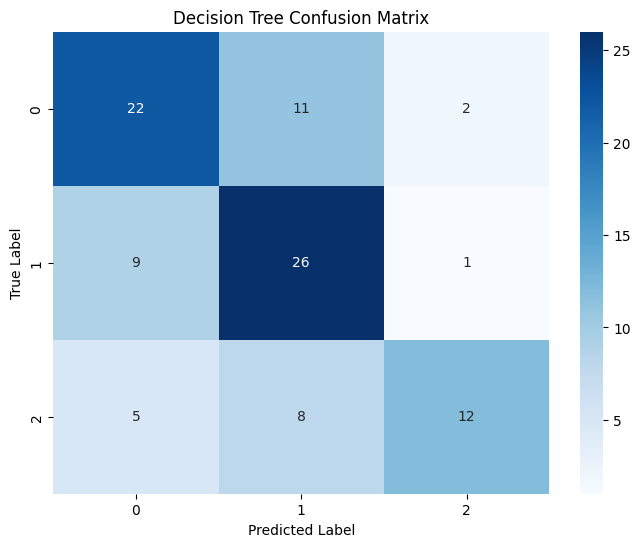

In [ ]:
# Decision Tree Classifier
model_dt = DecisionTreeClassifier(ccp_alpha=0.0, class_weight=None, criterion='entropy',
                                       max_depth=5, max_features=None, min_samples_leaf=2,
                                       min_samples_split=2, splitter='random', random_state=42) #Tuning Hyper-params
model_dt.fit(X_train, y_train)
y_pred_dt = model_dt.predict(X_test)

accuracy_dt = accuracy_score(y_test, y_pred_dt)
report_dt = classification_report(y_test, y_pred_dt)
cm_dt = confusion_matrix(y_test, y_pred_dt)

print(f"Decision Tree Classification - Accuracy: {accuracy_dt}")
print(f"Classification Report:\n{report_dt}")

# Visualize Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm_dt, annot=True, fmt="d", cmap="Blues")
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

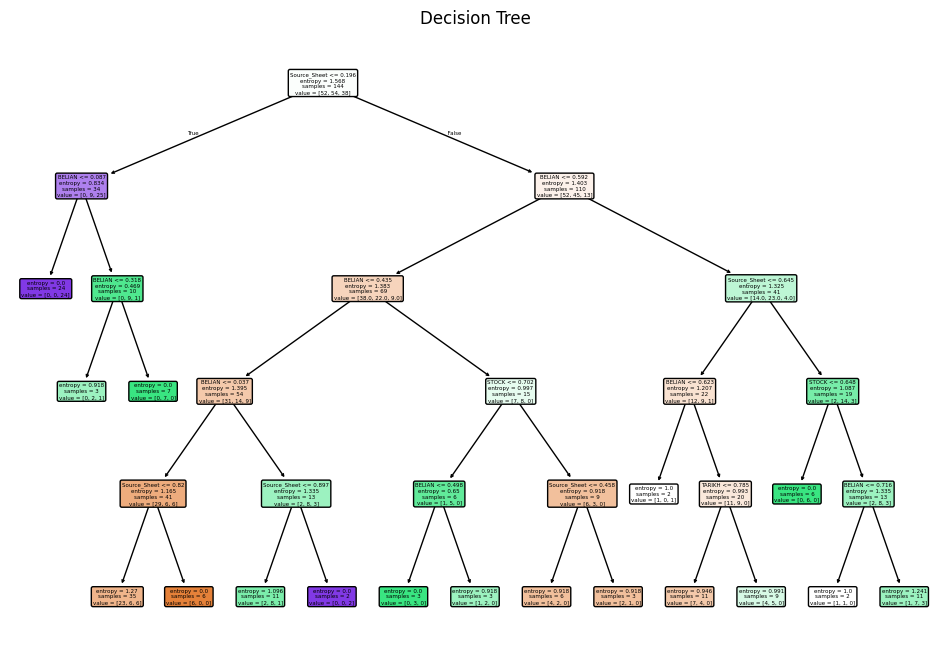

In [ ]:
# Visualize Decision Tree (if not too large)
plt.figure(figsize=(12, 8))
plot_tree(model_dt, feature_names=X_train.columns, filled=True, rounded=True, max_depth=5)
plt.title("Decision Tree")
plt.show()

**Random Forest Classifier**

Random Forest Classification - Accuracy: 0.6666666666666666
Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.66      0.66        35
           1       0.60      0.72      0.66        36
           2       0.83      0.60      0.70        25

    accuracy                           0.67        96
   macro avg       0.70      0.66      0.67        96
weighted avg       0.68      0.67      0.67        96



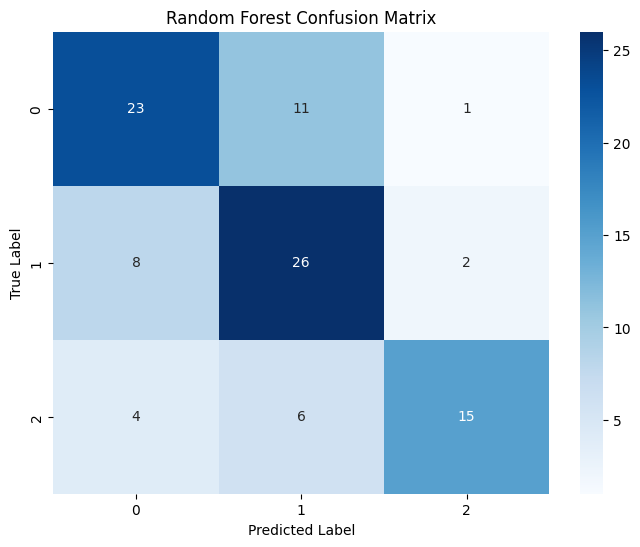

In [ ]:
model_rf = RandomForestClassifier(random_state=42, criterion="entropy", max_depth=10, n_estimators=700) #Tuning Hyper-params
model_rf.fit(X_train, y_train)
y_pred_rf = model_rf.predict(X_test)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
report_rf = classification_report(y_test, y_pred_rf)
cm_rf = confusion_matrix(y_test, y_pred_rf)

print(f"Random Forest Classification - Accuracy: {accuracy_rf}")
print(f"Classification Report:\n{report_rf}")

# Visualize Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

Classes corespond to High (2){200-1000+ RM}, Medium {75-200} (1), or Low(0) {0-75}  Sales

#**Feature Importance of Decision Tree and Random Forest**

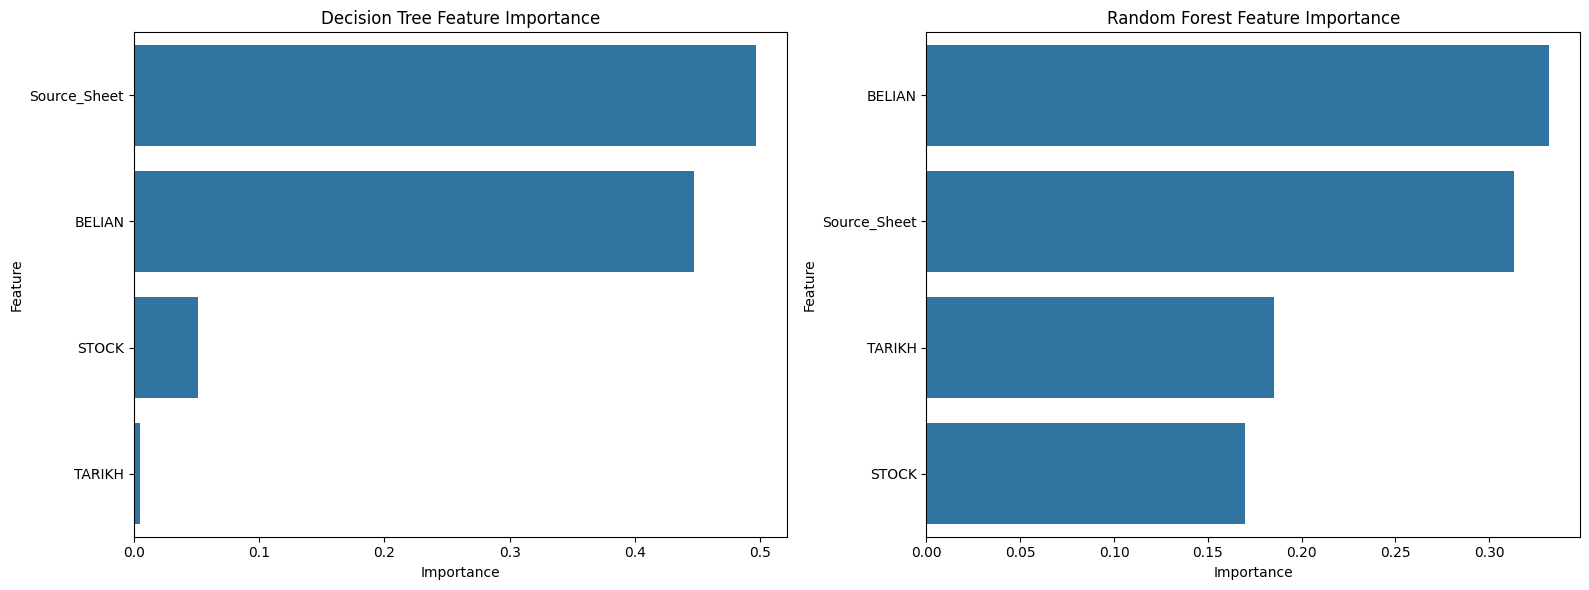

In [ ]:
# Decision Tree Feature Importance
feature_importances_dt = model_dt.feature_importances_

# Random Forest Feature Importance
feature_importances_rf = model_rf.feature_importances_

# Create DataFrames for plotting
df_dt_importance = pd.DataFrame({'Feature': X_train.columns, 'Importance': feature_importances_dt})
df_rf_importance = pd.DataFrame({'Feature': X_train.columns, 'Importance': feature_importances_rf})

# Sort by importance
df_dt_importance = df_dt_importance.sort_values(by='Importance', ascending=False)
df_rf_importance = df_rf_importance.sort_values(by='Importance', ascending=False)

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x='Importance', y='Feature', data=df_dt_importance, ax=axes[0])
axes[0].set_title("Decision Tree Feature Importance")

sns.barplot(x='Importance', y='Feature', data=df_rf_importance, ax=axes[1])
axes[1].set_title("Random Forest Feature Importance")

plt.tight_layout()
plt.show()

This means belian (price) is the biggest indicator of juluan (sales) followed by the month
(source_sheet), tarikh (date), Purchase cost, perkara (item), and bonus product

# **AUC and ROC for additional Performance Evaluation**

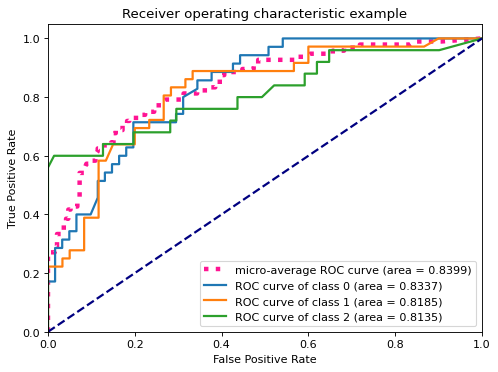

In [ ]:
#AUC and ROC for model evaluation
# Binarize the output
y_train_bin = label_binarize(y_train, classes=np.unique(y_train))
y_test_bin = label_binarize(y_test, classes=np.unique(y_train)) # use the same classes as y_train
n_classes = y_train_bin.shape[1]


# Learn to predict each class against the other
classifier = OneVsRestClassifier(model_rf)  # Using model_rf specifically
y_score = classifier.fit(X_train, y_train_bin).predict_proba(X_test)

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute micro-average ROC curve and ROC area
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# Visualize ROC curve for micro-average
plt.figure(figsize=(7, 5), dpi=80)
plt.plot(fpr["micro"], tpr["micro"],
         label='micro-average ROC curve (area = {0:0.4f})'
               ''.format(roc_auc["micro"]),
         color='deeppink', linestyle=':', linewidth=4)

# Visualize ROC curve for each class
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], lw=2,
             label='ROC curve of class {0} (area = {1:0.4f})'
             ''.format(i, roc_auc[i]))

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic example')
plt.legend(loc="lower right")
plt.show()

# **Naïve Bayes Model**

In [ ]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

# Create and train the Gaussian Naive Bayes model
model = GaussianNB()
model.fit(X_train, y_train)

# Predict and calculate accuracy
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)


Accuracy: 0.5416666666666666


# **Kernel SVM**

In [ ]:
# Generate synthetic dataset
X, y = make_classification(n_samples=1000, n_features=20, n_informative=15, n_redundant=5, random_state=42)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Define the Kernel SVM model
svm_model = SVC(kernel='rbf', C=1, gamma='scale', random_state=42)

# Train the model
svm_model.fit(X_train, y_train)

# Make predictions
y_pred = svm_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

# Print the accuracy and classification report
print(f"Kernel SVM Accuracy: {accuracy:.2f}")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Kernel SVM Accuracy: 0.94
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.92      0.94       106
           1       0.91      0.97      0.94        94

    accuracy                           0.94       200
   macro avg       0.94      0.94      0.94       200
weighted avg       0.94      0.94      0.94       200



#**Determining Best-Selling Product from SVM Kernel Model**

Kernel SVM Accuracy: 0.98
Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99        33
           1       1.00      0.93      0.97        15

    accuracy                           0.98        48
   macro avg       0.99      0.97      0.98        48
weighted avg       0.98      0.98      0.98        48

Top Best-Selling Products:
    PERKARA   0   1        JUALAN  Best_Seller_Score
12       12  18  17  14857.718084       14857.718084
25       25   4   9   8545.705882        8545.705882
4         4   4   9   8496.558824        8496.558824
2         2  20   7   3897.875000        3897.875000
1         1  21   3   3186.728461        3186.728461
5         5   1   4   2737.787115        2737.787115
24       24   9   2   2105.940476        2105.940476
7         7  11   3   1995.017698        1995.017698
0         0  12   2   1675.166667        1675.166667
3         3   9   2   1661.865079        1661.865079


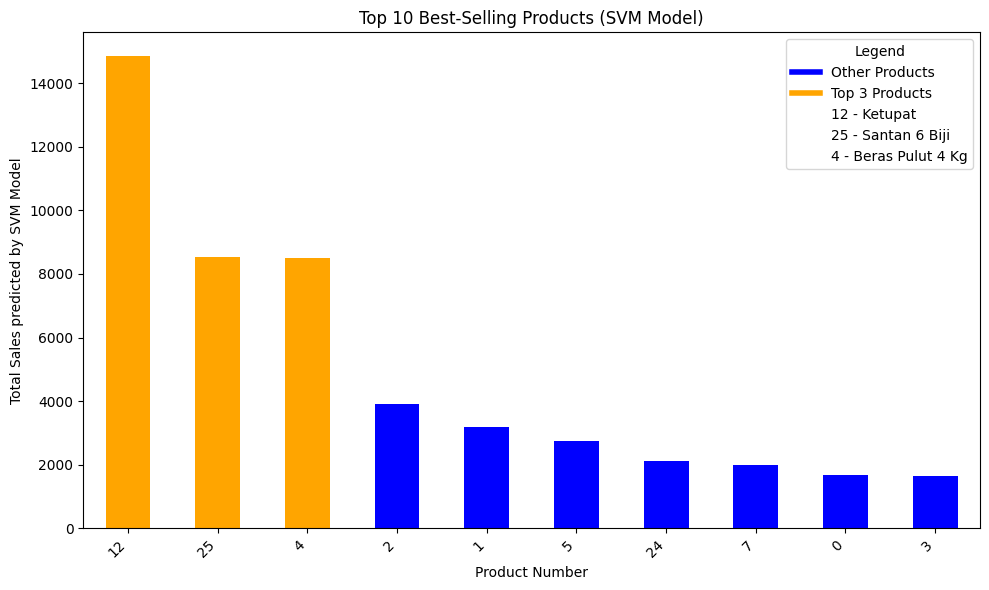

In [ ]:
X = data[['JUALAN', 'STOCK']]  # Features
data['Best_Seller_Label'] = (data['JUALAN'] > 150).astype(int)

y = data['Best_Seller_Label']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define and Train the SVM Kernel Model
svm_model = SVC(kernel='rbf', C=1, gamma='scale', random_state=42)
svm_model.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred = svm_model.predict(X_test_scaled)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Kernel SVM Accuracy: {accuracy:.2f}")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Aggregate SVM Kernel Predictions by Product
X_for_svm = data[['JUALAN', 'STOCK']]

# Standardize only the selected features before prediction
scaler_svm = StandardScaler()
X_for_svm_scaled = scaler_svm.fit_transform(X_for_svm)

# Make predictions on the dataset
predictions_svm = svm_model.predict(X_for_svm_scaled)
data['SVM_Predictions'] = predictions_svm  # Add predictions to the original dataset

# Group by Product and Count Predictions for Each Category
product_predictions = data.groupby('PERKARA')['SVM_Predictions'].value_counts().unstack(fill_value=0)

# Calculate Total Sales for Each Product
total_sales = data.groupby('PERKARA')['JUALAN'].sum().reset_index()

# Merge predictions with total sales
product_analysis = product_predictions.merge(total_sales, on='PERKARA', how='left')

# Rank Products Based on Combined Metrics
product_analysis['Best_Seller_Score'] = product_analysis['JUALAN']  # Total sales used as score

# Sort products by the best-seller score
best_selling_products = product_analysis.sort_values(by='Best_Seller_Score', ascending=False)

# Display Top Products
print("Top Best-Selling Products:")
print(best_selling_products.head(10))

# Visualization
# Highlight the Top Product with a different color
top_products = best_selling_products.head(10)
colors = ['orange' if i in top_products.index[:3] else 'blue' for i in top_products.index]

# Bar chart for the SVM Kernel Model
ax = top_products.plot(
    x='PERKARA',
    y='Best_Seller_Score',
    kind='bar',
    color=colors,
    figsize=(10, 6),
    title='Top 10 Best-Selling Products (SVM Model)'
)
plt.ylabel('Total Sales')

# Legend
handles = [
    plt.Line2D([0], [0], color='blue', lw=4, label='Other Products'),
    plt.Line2D([0], [0], color='orange', lw=4, label='Top 3 Products'),
    plt.Line2D([0], [0], color='white', lw=4, label='12 - Ketupat'),
    plt.Line2D([0], [0], color='white', lw=4, label='25 - Santan 6 Biji'),
    plt.Line2D([0], [0], color='white', lw=4, label='4 - Beras Pulut 4 Kg')
]
ax.legend(handles=handles, title="Legend")

# Adjust layout and labels
ax.set_xlabel("Product Number")
ax.set_ylabel("Total Sales predicted by SVM Model")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
